In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

/tmp/ipykernel_24617/687462750.py:1: DeprecationWarning: 
Pyarrow will become a required dependency of pandas in the next major release of pandas (pandas 3.0),
(to allow more performant data types, such as the Arrow string type, and better interoperability with other libraries)
but was not found to be installed on your system.
If this would cause problems for you,
please provide us feedback at https://github.com/pandas-dev/pandas/issues/54466
        
  import pandas as pd


In [2]:
DATA_PATH = '../../data'
MERGEGEN_RESULTS = '../../mergeGen/RESULTS'
SBCR_RESULTS = '../../sbcr'

MERGEGEN_DATASET1 = f"{MERGEGEN_RESULTS}/mergeGen_dataset1_model_dataset1_similarities.csv"
MERGEGEN_DATASET2 = f"{MERGEGEN_RESULTS}/mergeGen_dataset1_model_dataset2_Java_similarities.csv"

SBCR_DATASET1 = f"{SBCR_RESULTS}/rq1_dataset1/RESULTS/results_evaluate_dataset1_rq1_dataset1_seed-3022024.xlsx"
SBCR_DATASET2 = f"{SBCR_RESULTS}/rq3_dataset1/RESULTS/results_evaluate_dataset1_rq3_dataset1_seed-3022024.xlsx"

DATASET1_COMPLETE = f"{DATA_PATH}/dataset1_complete.json" 

## Evaluation on Dataset1

### SBCR tuned on Dataset1 vs SBCR tuned on Dataset2_Java

In [3]:
df_sbcr_dataset2 = pd.read_excel(SBCR_DATASET2)
df_sbcr_dataset2 = df_sbcr_dataset2.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_dataset2.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
548,776942,0.738426,1.000000,ok,0.951203
304,777222,0.890922,0.995192,ok,1.081496
186,777715,0.769506,1.000000,ok,0.252092
585,777972,0.739558,0.918239,ok,3.992651
257,777981,0.493671,1.000000,ok,1.696486
...,...,...,...,...,...
468,1653719,0.702732,1.000000,ok,0.986550
140,1653901,0.441073,0.160979,ok,2.589546
296,1656072,0.498986,0.810680,ok,19.540492
530,1656401,0.901249,0.788274,ok,1.657524


In [4]:
df_sbcr_dataset1 = pd.read_excel(SBCR_DATASET1)
df_sbcr_dataset1 = df_sbcr_dataset1.rename(columns={"solution_sim_lcs": "sim_sbcr", "time_seconds": "time_sbcr", "fitness": "fitness_sbcr"})
df_sbcr_dataset1.sort_values('chunk_id')

,chunk_id,fitness_sbcr,sim_sbcr,status,time_sbcr
548,776942,0.738426,1.000000,ok,1.489457
304,777222,0.890922,0.995192,ok,0.841280
186,777715,0.776531,0.985915,ok,0.333870
585,777972,0.739558,0.918239,ok,2.215153
257,777981,0.493671,1.000000,ok,1.991492
...,...,...,...,...,...
468,1653719,0.702732,1.000000,ok,1.030614
140,1653901,0.492901,0.192205,ok,6.408932
296,1656072,0.498986,0.810680,ok,12.752023
530,1656401,0.901249,0.788274,ok,0.941998


In [5]:
df_sbcr = df_sbcr_dataset1.merge(df_sbcr_dataset2, on='chunk_id', suffixes=('_ds1', '_ds2'))
df_sbcr

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2
0,938488,0.962434,0.922330,ok,1.200660,0.962434,0.922330,ok,0.499819
1,1079827,0.497797,0.625767,ok,11.268360,0.497797,0.625767,ok,22.677319
2,1117164,0.786942,0.786232,ok,1.923556,0.786942,0.786232,ok,0.333692
3,945817,0.795430,0.819499,ok,1.355437,0.794816,0.739018,ok,0.557985
4,1304099,0.459559,0.763636,ok,8.889821,0.459559,0.781818,ok,1.948936
...,...,...,...,...,...,...,...,...,...
623,938165,0.819818,1.000000,ok,10.783195,0.819818,1.000000,ok,15.428857
624,1517141,0.901249,0.788274,ok,0.200084,0.901249,0.788274,ok,1.100036
625,934974,0.897614,0.857708,ok,0.521170,0.897958,0.873294,ok,0.329665
626,1180810,0.591401,0.915108,ok,1.287984,0.586344,0.933333,ok,0.523076


In [6]:
df_sbcr_clean = df_sbcr.dropna(subset=['sim_sbcr_ds1', 'sim_sbcr_ds2'])
df_sbcr_clean

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2
0,938488,0.962434,0.922330,ok,1.200660,0.962434,0.922330,ok,0.499819
1,1079827,0.497797,0.625767,ok,11.268360,0.497797,0.625767,ok,22.677319
2,1117164,0.786942,0.786232,ok,1.923556,0.786942,0.786232,ok,0.333692
3,945817,0.795430,0.819499,ok,1.355437,0.794816,0.739018,ok,0.557985
4,1304099,0.459559,0.763636,ok,8.889821,0.459559,0.781818,ok,1.948936
...,...,...,...,...,...,...,...,...,...
623,938165,0.819818,1.000000,ok,10.783195,0.819818,1.000000,ok,15.428857
624,1517141,0.901249,0.788274,ok,0.200084,0.901249,0.788274,ok,1.100036
625,934974,0.897614,0.857708,ok,0.521170,0.897958,0.873294,ok,0.329665
626,1180810,0.591401,0.915108,ok,1.287984,0.586344,0.933333,ok,0.523076


In [7]:
print(df_sbcr_clean[['sim_sbcr_ds1', 'sim_sbcr_ds2', 'time_sbcr_ds1', 'time_sbcr_ds2']].describe())

       sim_sbcr_ds1  sim_sbcr_ds2  time_sbcr_ds1  time_sbcr_ds2
count    628.000000    628.000000     628.000000     628.000000
mean       0.809004      0.810372       4.786695       5.440525
std        0.200003      0.200595       4.913480       7.362097
min        0.075646      0.063344       0.100592       0.062037
25%        0.687125      0.680228       0.692114       0.382334
50%        0.865125      0.864969       2.556238       1.635699
75%        1.000000      1.000000      10.520015       8.675346
max        1.000000      1.000000      45.932123      59.175786


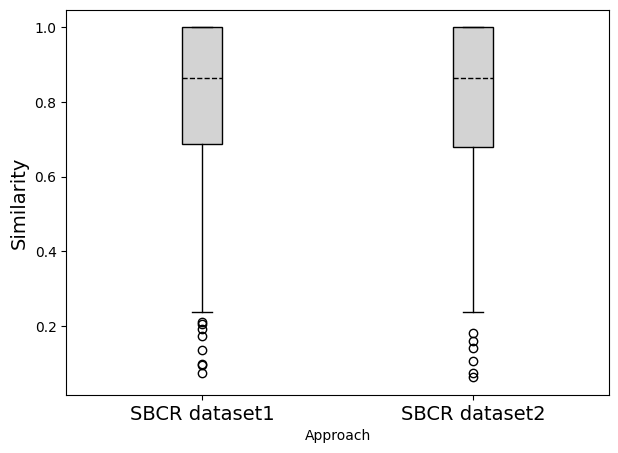

In [8]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_sbcr_clean['sim_sbcr_ds1'], df_sbcr_clean['sim_sbcr_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR dataset1', 'SBCR dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

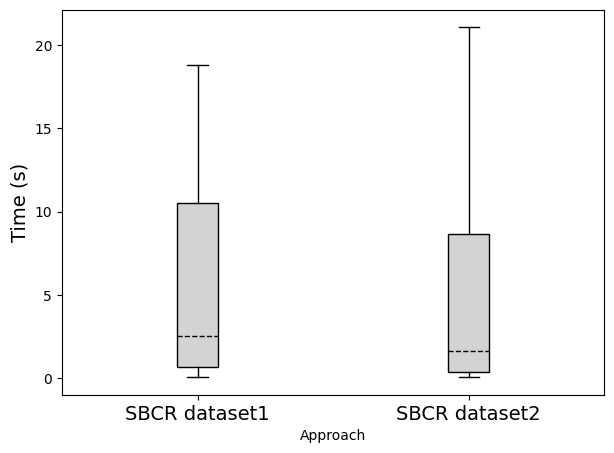

In [9]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_sbcr_clean['time_sbcr_ds1'], df_sbcr_clean['time_sbcr_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)

plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR dataset1', 'SBCR dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

### MergeGen trained on Dataset1 vs MergeGen trained on Dataset2_Java

In [10]:
df_complete = pd.read_json(DATASET1_COMPLETE)

In [11]:
df_mergegen_ds1 = pd.read_csv(MERGEGEN_DATASET1)
df_mergegen_ds1['chunk_id'] = df_mergegen_ds1['chunk_index'].apply(lambda idx: df_complete.loc[idx, 'chunk_id'])
df_mergegen_ds1 = df_mergegen_ds1.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds1.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
187,4,1.000000,1.000000,0.249119,0.512563,0.972222,0.742393,SUCCEED,776942
178,7,1.000000,0.994764,0.233733,0.933702,0.838906,0.886304,SUCCEED,777222
446,19,0.967742,1.000000,0.751554,0.973190,0.551456,0.762323,SUCCEED,777715
145,53,0.530120,0.545455,0.163389,0.321429,0.724138,0.522783,FAIL,777972
152,55,0.752577,0.804533,1.326094,0.000000,0.802260,0.401130,FAIL,777981
...,...,...,...,...,...,...,...,...,...
449,6208,1.000000,1.000000,0.254737,0.981308,0.437956,0.709632,SUCCEED,1653719
4,6210,0.250373,0.259194,1.323702,0.000000,0.510092,0.255046,FAIL,1653901
314,6228,1.000000,1.000000,0.153870,0.000000,0.821918,0.410959,SUCCEED,1656072
602,6236,1.000000,1.000000,0.280683,0.923977,0.858696,0.891336,SUCCEED,1656401


In [12]:
df_mergegen_ds2 = pd.read_csv(MERGEGEN_DATASET2)
df_mergegen_ds2['chunk_id'] = df_mergegen_ds2['chunk_index'].apply(lambda idx: df_complete.loc[idx, 'chunk_id'])
df_mergegen_ds2 = df_mergegen_ds2.rename(columns={"complete_similarity": "sim_mergegen", "time": "time_mergegen", "similarity":"sim_mergegen_trunc", "parents_similarity":"mergegen_parents_sim"})
df_mergegen_ds2.sort_values('chunk_id')

,chunk_index,sim_mergegen_trunc,sim_mergegen,time_mergegen,v1_similarity,v2_similarity,mergegen_parents_sim,result,chunk_id
207,4,1.000000,1.000000,0.237083,0.512563,0.972222,0.742393,SUCCEED,776942
197,7,1.000000,0.994764,0.231553,0.933702,0.838906,0.886304,SUCCEED,777222
446,19,0.967742,1.000000,0.743293,0.973190,0.551456,0.762323,SUCCEED,777715
581,53,1.000000,1.000000,0.161723,0.769231,0.645161,0.707196,SUCCEED,777972
166,55,0.775300,0.844193,1.308893,0.000000,0.841808,0.420904,FAIL,777981
...,...,...,...,...,...,...,...,...,...
449,6208,1.000000,1.000000,0.253104,0.981308,0.437956,0.709632,SUCCEED,1653719
3,6210,0.000000,0.000000,1.318811,1.000000,0.000000,0.500000,FAIL,1653901
322,6228,1.000000,1.000000,0.147711,0.000000,0.821918,0.410959,SUCCEED,1656072
606,6236,1.000000,1.000000,0.271338,0.923977,0.858696,0.891336,SUCCEED,1656401


In [13]:
df_mergegen = df_mergegen_ds1.merge(df_mergegen_ds2, on='chunk_id', suffixes=('_ds1', '_ds2'))
df_mergegen

,chunk_index_ds1,sim_mergegen_trunc_ds1,sim_mergegen_ds1,time_mergegen_ds1,v1_similarity_ds1,v2_similarity_ds1,mergegen_parents_sim_ds1,result_ds1,chunk_id,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,5019,0.259615,0.272222,0.117003,1.000000,0.252577,0.626289,FAIL,1311711,5019,1.000000,1.000000,0.589828,0.272222,0.956923,0.614573,SUCCEED
1,3899,0.733333,0.741379,0.116758,0.593103,0.000000,0.296552,FAIL,1128493,3899,0.733333,0.741379,0.259596,0.593103,0.000000,0.296552,FAIL
2,4351,0.710843,0.716981,0.130520,0.000000,0.716981,0.358491,FAIL,1161479,4351,0.710843,0.716981,0.128615,0.000000,0.716981,0.358491,FAIL
3,5574,0.657143,0.671642,0.123770,0.494382,0.537143,0.515762,FAIL,1412463,5574,1.000000,1.000000,0.456007,0.494382,0.754286,0.624334,SUCCEED
4,6210,0.250373,0.259194,1.323702,0.000000,0.510092,0.255046,FAIL,1653901,6210,0.000000,0.000000,1.318811,1.000000,0.000000,0.500000,FAIL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
623,5998,0.685417,0.804124,1.324466,0.764862,0.732394,0.748628,SUCCEED,1517142,5998,0.685417,0.725237,1.312014,0.683274,0.837647,0.760461,FAIL
624,4227,0.662712,0.754717,1.319163,0.446171,0.769032,0.607602,SUCCEED,1157334,4227,0.635772,0.798780,1.308019,0.403888,0.806250,0.605069,SUCCEED
625,5516,1.000000,1.000000,0.227891,0.615942,0.800000,0.707971,SUCCEED,1406283,5516,1.000000,1.000000,0.363034,0.615942,0.800000,0.707971,SUCCEED
626,814,0.685417,0.804124,1.318304,0.764862,0.732394,0.748628,SUCCEED,840920,814,0.685417,0.725237,1.306404,0.683274,0.837647,0.760461,FAIL


In [14]:
df_mergegen_clean = df_mergegen.dropna(subset=['sim_mergegen_ds1', 'sim_mergegen_ds2'])
df_mergegen_clean

,chunk_index_ds1,sim_mergegen_trunc_ds1,sim_mergegen_ds1,time_mergegen_ds1,v1_similarity_ds1,v2_similarity_ds1,mergegen_parents_sim_ds1,result_ds1,chunk_id,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,5019,0.259615,0.272222,0.117003,1.000000,0.252577,0.626289,FAIL,1311711,5019,1.000000,1.000000,0.589828,0.272222,0.956923,0.614573,SUCCEED
1,3899,0.733333,0.741379,0.116758,0.593103,0.000000,0.296552,FAIL,1128493,3899,0.733333,0.741379,0.259596,0.593103,0.000000,0.296552,FAIL
2,4351,0.710843,0.716981,0.130520,0.000000,0.716981,0.358491,FAIL,1161479,4351,0.710843,0.716981,0.128615,0.000000,0.716981,0.358491,FAIL
3,5574,0.657143,0.671642,0.123770,0.494382,0.537143,0.515762,FAIL,1412463,5574,1.000000,1.000000,0.456007,0.494382,0.754286,0.624334,SUCCEED
4,6210,0.250373,0.259194,1.323702,0.000000,0.510092,0.255046,FAIL,1653901,6210,0.000000,0.000000,1.318811,1.000000,0.000000,0.500000,FAIL
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
623,5998,0.685417,0.804124,1.324466,0.764862,0.732394,0.748628,SUCCEED,1517142,5998,0.685417,0.725237,1.312014,0.683274,0.837647,0.760461,FAIL
624,4227,0.662712,0.754717,1.319163,0.446171,0.769032,0.607602,SUCCEED,1157334,4227,0.635772,0.798780,1.308019,0.403888,0.806250,0.605069,SUCCEED
625,5516,1.000000,1.000000,0.227891,0.615942,0.800000,0.707971,SUCCEED,1406283,5516,1.000000,1.000000,0.363034,0.615942,0.800000,0.707971,SUCCEED
626,814,0.685417,0.804124,1.318304,0.764862,0.732394,0.748628,SUCCEED,840920,814,0.685417,0.725237,1.306404,0.683274,0.837647,0.760461,FAIL


In [15]:
print(df_mergegen_clean[['sim_mergegen_ds1', 'sim_mergegen_ds2', 'time_mergegen_ds1', 'time_mergegen_ds2']].describe())

       sim_mergegen_ds1  sim_mergegen_ds2  time_mergegen_ds1  \
count        628.000000        628.000000         628.000000   
mean           0.923022          0.901936           0.397476   
std            0.153027          0.194034           0.339692   
min            0.082251          0.000000           0.051868   
25%            0.940939          0.895390           0.156820   
50%            1.000000          1.000000           0.277324   
75%            1.000000          1.000000           0.509618   
max            1.000000          1.000000           1.331165   

       time_mergegen_ds2  
count         628.000000  
mean            0.421549  
std             0.345472  
min             0.051200  
25%             0.180887  
50%             0.291519  
75%             0.517710  
max             1.320650  


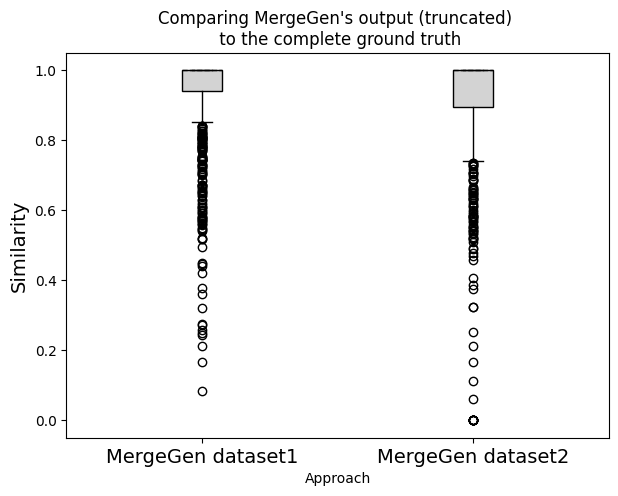

In [16]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_mergegen_clean['sim_mergegen_ds1'], df_mergegen_clean['sim_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)
plt.title("Comparing MergeGen's output (truncated) \n to the complete ground truth")
plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['MergeGen dataset1', 'MergeGen dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

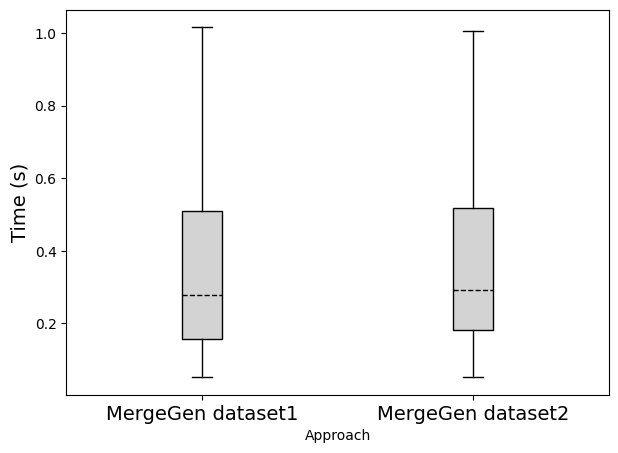

In [17]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_mergegen_clean['time_mergegen_ds1'], df_mergegen_clean['time_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)
plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['MergeGen dataset1', 'MergeGen dataset2'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

### SBCR trained on Dataset2_Java vs MergeGen trained on Dataset2_Java


In [18]:
df_both = df_sbcr_clean.merge(df_mergegen_clean, on='chunk_id')
df_both

,chunk_id,fitness_sbcr_ds1,sim_sbcr_ds1,status_ds1,time_sbcr_ds1,fitness_sbcr_ds2,sim_sbcr_ds2,status_ds2,time_sbcr_ds2,chunk_index_ds1,...,mergegen_parents_sim_ds1,result_ds1,chunk_index_ds2,sim_mergegen_trunc_ds2,sim_mergegen_ds2,time_mergegen_ds2,v1_similarity_ds2,v2_similarity_ds2,mergegen_parents_sim_ds2,result_ds2
0,938488,0.962434,0.922330,ok,1.200660,0.962434,0.922330,ok,0.499819,1471,...,0.958965,SUCCEED,1471,1.000000,1.000000,0.173634,0.959596,0.958333,0.958965,SUCCEED
1,1079827,0.497797,0.625767,ok,11.268360,0.497797,0.625767,ok,22.677319,3195,...,0.318471,SUCCEED,3195,1.000000,1.000000,0.220310,0.000000,0.636943,0.318471,SUCCEED
2,1117164,0.786942,0.786232,ok,1.923556,0.786942,0.786232,ok,0.333692,3761,...,0.670922,FAIL,3761,0.759777,0.750751,0.225828,0.750751,0.591093,0.670922,FAIL
3,945817,0.795430,0.819499,ok,1.355437,0.794816,0.739018,ok,0.557985,1594,...,0.757170,FAIL,1594,1.000000,0.967532,0.535932,0.818692,0.721910,0.770301,SUCCEED
4,1304099,0.459559,0.763636,ok,8.889821,0.459559,0.781818,ok,1.948936,4944,...,0.397321,SUCCEED,4944,1.000000,1.000000,0.291603,0.794643,0.000000,0.397321,SUCCEED
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
623,938165,0.819818,1.000000,ok,10.783195,0.819818,1.000000,ok,15.428857,1443,...,0.819331,SUCCEED,1443,1.000000,1.000000,0.193674,0.674699,0.963964,0.819331,SUCCEED
624,1517141,0.901249,0.788274,ok,0.200084,0.901249,0.788274,ok,1.100036,5997,...,0.891336,SUCCEED,5997,1.000000,1.000000,0.270959,0.923977,0.858696,0.891336,SUCCEED
625,934974,0.897614,0.857708,ok,0.521170,0.897958,0.873294,ok,0.329665,1221,...,0.915444,SUCCEED,1221,1.000000,1.000000,0.458846,0.867925,0.962963,0.915444,SUCCEED
626,1180810,0.591401,0.915108,ok,1.287984,0.586344,0.933333,ok,0.523076,4423,...,0.566233,SUCCEED,4423,0.669291,0.875666,1.304728,0.859474,0.166181,0.512827,SUCCEED


In [19]:
print(df_both[['sim_sbcr_ds2', 'sim_mergegen_ds2', 'sim_mergegen_trunc_ds2', 'time_sbcr_ds2', 'time_mergegen_ds2']].describe())

       sim_sbcr_ds2  sim_mergegen_ds2  sim_mergegen_trunc_ds2  time_sbcr_ds2  \
count    628.000000        628.000000              628.000000     628.000000   
mean       0.810372          0.901936                0.899636       5.440525   
std        0.200595          0.194034                0.194803       7.362097   
min        0.063344          0.000000                0.000000       0.062037   
25%        0.680228          0.895390                0.863059       0.382334   
50%        0.864969          1.000000                1.000000       1.635699   
75%        1.000000          1.000000                1.000000       8.675346   
max        1.000000          1.000000                1.000000      59.175786   

       time_mergegen_ds2  
count         628.000000  
mean            0.421549  
std             0.345472  
min             0.051200  
25%             0.180887  
50%             0.291519  
75%             0.517710  
max             1.320650  


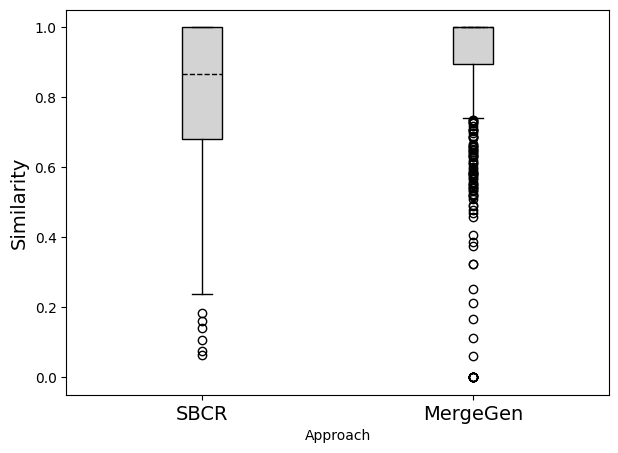

In [20]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_both['sim_sbcr_ds2'], df_mergegen_clean['sim_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=True)

plt.xlabel('Approach')
plt.ylabel('Similarity', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  

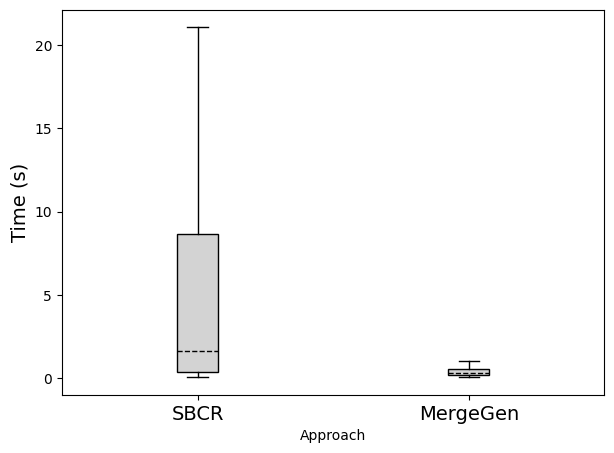

In [21]:
plt.figure(figsize=(7, 5)) 
plt.boxplot([df_both['time_sbcr_ds2'], df_both['time_mergegen_ds2']], 
            patch_artist=True, 
#             widths=0.5,  # Width of the box
            medianprops=dict(color='black', linestyle='--'),  
            boxprops=dict(facecolor='lightgray', color='black'),  
            whiskerprops=dict(color='black'),
            capprops=dict(color='black'),  
            showfliers=False)
plt.xlabel('Approach')
plt.ylabel('Time (s)', fontsize=14)
plt.xticks([1, 2], ['SBCR', 'MergeGen'], fontsize=14)

# plt.savefig('RQ3_boxplots.png', dpi=300) 
plt.show()  